Importação de bibliotecas

In [1]:
!pip install ucimlrepo -q

import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

Carga do dataset e amostragem inicial

In [2]:
adult = fetch_ucirepo(id=2)

X = adult.data.features
y = adult.data.targets

dataset = pd.concat([X, y], axis=1)
dataset.columns = dataset.columns.str.strip()

display(dataset.head())

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


Normalização do dataset

In [3]:
# Remover espaços dos valores textuais
for col in dataset.select_dtypes(include="object").columns:
    dataset[col] = dataset[col].str.strip()

# Remover a coluna fnlwgt
dataset = dataset.drop(columns=["fnlwgt"], errors="ignore")

# Substituir '?' por valores ausentes
dataset = dataset.replace("?", np.nan)

# Identificar a variável-alvo
target_column = "income"

# Limpar a variável-alvo
dataset[target_column] = (
    dataset[target_column]
    .astype(str)
    .str.strip()
    .str.replace(r"\.$", "", regex=True)
)

# Remover registros sem classificação de renda
dataset = dataset.dropna(subset=[target_column])

# Separar variáveis independentes e dependente
X = dataset.drop(columns=[target_column])
y = dataset[target_column]

In [4]:
# Identificar colunas numéricas
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identificar colunas categóricas
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Variáveis numéricas:", numeric_features)
print("\nVariáveis categóricas:", categorical_features)

# Tratamento das variáveis numéricas
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Tratamento das variáveis categóricas
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combinar os tratamentos
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

Variáveis numéricas: ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Variáveis categóricas: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


Divisão de dados de treino e teste

In [5]:
# Divisão dos dados
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Dados de treinamento:", X_train.shape)
print("Dados de teste:", X_test.shape)

print("\nDistribuição do treinamento:")
print(y_train.value_counts(normalize=True).round(3))

print("\nDistribuição do teste:")
print(y_test.value_counts(normalize=True).round(3))

Dados de treinamento: (34189, 13)
Dados de teste: (14653, 13)

Distribuição do treinamento:
income
<=50K    0.761
>50K     0.239
Name: proportion, dtype: float64

Distribuição do teste:
income
<=50K    0.761
>50K     0.239
Name: proportion, dtype: float64


Treinamento do modelo

In [6]:
# Criar o classificador Random Forest
clf = RandomForestClassifier(
    n_estimators=100,
    criterion="entropy",
    max_features="sqrt",
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

# Criar pipeline completo
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", clf)
])

# Treinar o modelo
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['age', 'education-num',
                                                   'capital-gain',
                                                   'capital-loss',
                                                   'hours-per-week']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['workclass', 'education',
                                                   'marital-status',
                                                   'occupation', 'relationship',
                                                   'race', 'sex',
                                                   'native-country'])])),
                ('classifier',
                 RandomForestClassifier(criterion='entropy', n_jobs=-1,
                                        random_state=42))])

Teste de previsões

In [13]:
# Medir o tempo de execução das previsões
inicio_predicao = time.perf_counter()

y_pred = model.predict(X_test)

fim_predicao = time.perf_counter()

# Calcular o tempo total de predição
tempo_predicao = fim_predicao - inicio_predicao

# Calcular o tempo médio por registro
tempo_medio = tempo_predicao / len(X_test)

# Exibir os tempos
print("TEMPO DE PREDIÇÃO - ÁRVORE DE DECISÃO")
print("------------------------------------")
print(f"Tempo total de predição: {tempo_predicao:.6f} segundos")
print("------------------------------------")

# Realizar previsões com os dados de teste
y_pred = model.predict(X_test)

# Visualizar algumas previsões
resultados = pd.DataFrame({
    "Valor Real": y_test.values,
    "Valor Previsto": y_pred
})

display(resultados.head(20))

TEMPO DE PREDIÇÃO - ÁRVORE DE DECISÃO
------------------------------------
Tempo total de predição: 0.319001 segundos
------------------------------------


,Valor Real,Valor Previsto
0,<=50K,<=50K
1,<=50K,<=50K
2,<=50K,<=50K
3,<=50K,<=50K
4,<=50K,<=50K
5,<=50K,<=50K
6,>50K,<=50K
7,<=50K,<=50K
8,<=50K,<=50K
9,<=50K,<=50K


Cálculo das métricas de acurácia

In [8]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    pos_label=">50K"
)

recall = recall_score(
    y_test,
    y_pred,
    pos_label=">50K"
)

f1 = f1_score(
    y_test,
    y_pred,
    pos_label=">50K"
)

# Exibir resultados
print("AVALIAÇÃO DO MODELO - RANDOM FOREST")
print("-----------------------------------")

print(f"Acurácia:  {accuracy:.4f}")
print(f"Precisão:  {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred))

AVALIAÇÃO DO MODELO - RANDOM FOREST
-----------------------------------
Acurácia:  0.8462
Precisão:  0.7011
Recall:    0.6229
F1-Score:  0.6597

Relatório de classificação:
              precision    recall  f1-score   support

       <=50K       0.89      0.92      0.90     11147
        >50K       0.70      0.62      0.66      3506

    accuracy                           0.85     14653
   macro avg       0.79      0.77      0.78     14653
weighted avg       0.84      0.85      0.84     14653



Matrix de acurácia das respostas


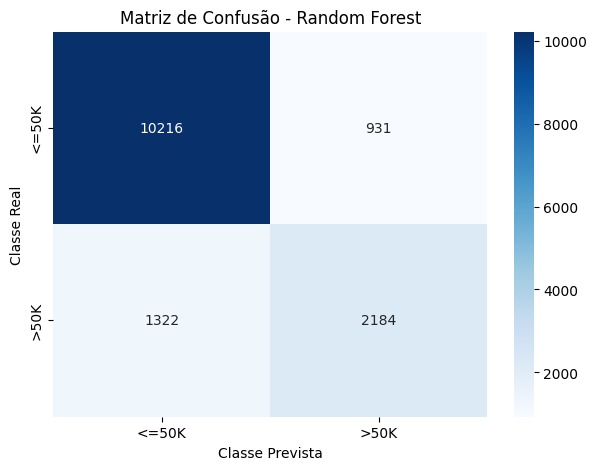

In [9]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["<=50K", ">50K"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["<=50K", ">50K"],
    yticklabels=["<=50K", ">50K"]
)

plt.title("Matriz de Confusão - Random Forest")
plt.xlabel("Classe Prevista")
plt.ylabel("Classe Real")
plt.show()

Importância de cada variável para a decisão

In [11]:
# Extrair a árvore treinada do pipeline
arvore = model.named_steps["classifier"]

# Obter os nomes das variáveis após o pré-processamento
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Obter a importância de cada variável
importances = arvore.feature_importances_

# Associar cada variável transformada à variável original
variaveis_originais = []

for nome in feature_names:
    nome_limpo = nome.split("__", 1)[-1]

    # Identificar a variável categórica de origem
    correspondencias = [
        col for col in categorical_features
        if nome_limpo.startswith(col + "_")
    ]

    if correspondencias:
        variavel = max(correspondencias, key=len)
    else:
        variavel = nome_limpo

    variaveis_originais.append(variavel)

# Criar o DataFrame de importância
feature_importance = pd.DataFrame({
    "Variável Original": variaveis_originais,
    "Importância": importances
})

# Agrupar as importâncias por variável original
importance_grouped = (
    feature_importance
    .groupby("Variável Original")["Importância"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# Converter a importância para percentual
importance_grouped["Importância (%)"] = (
    importance_grouped["Importância"] * 100
)

# Exibir as 15 variáveis originais mais importantes
display(
    importance_grouped.head(15)[
        ["Variável Original", "Importância (%)"]
    ].style.format({
        "Importância (%)": "{:.2f}%"
    }).background_gradient(
        subset=["Importância (%)"],
        cmap="Blues"
    )
)


,Variável Original,Importância (%)
0,age,24.59%
1,hours-per-week,12.06%
2,marital-status,10.34%
3,capital-gain,9.70%
4,relationship,9.34%
5,occupation,8.44%
6,education-num,5.91%
7,education,5.69%
8,workclass,4.31%
9,capital-loss,3.25%
